# Regresión logística: desde la intuición hasta la interpretación exhaustiva

**Guía docente autocontenida · Clasificación supervisada · Google Colab**

Este notebook sigue la progresión de `01-logistica-intuicion.ipynb`: partir de un objetivo binario (aprueba/no aprueba), observar por qué una recta no produce probabilidades válidas, comprender sigmoide, logit, entropía cruzada, descenso del gradiente y odds ratios; después entrenar y evaluar una **regresión logística** con datos nuevos.

**Objetivo:** comprender **cada bloque de código**, el origen de los resultados numéricos, las operaciones que permiten reproducirlos, el significado de las tablas y las gráficas y los límites de las conclusiones. Se incluyen matriz de confusión, accuracy, precision, recall, F1, ROC-AUC, average precision, calibración, umbrales y validación cruzada estratificada.

**Base:** 600 estudiantes **ficticios** generados con semilla fija; no requiere CSV. Son ejemplos pedagógicos y no deben utilizarse para tomar decisiones sobre estudiantes reales.

**Método de estudio:** ejecuta una celda y lee la explicación inmediatamente posterior. Los datos de prueba se mantienen separados del ajuste y la validación.


## 0. Relación con el notebook original y ruta de aprendizaje

El notebook entregado por el docente, `01-logistica-intuicion.ipynb`, desarrolla la intuición de clasificación binaria, el paso de una recta a la sigmoide, las probabilidades, la entropía cruzada, el gradiente, las razones de momios, softmax y separación perfecta.

Aquí retomamos **exclusivamente la regresión logística** y profundizamos con una base generada en el propio Colab, interpretación detallada de coeficientes y predicciones manuales, evaluación de clasificación y validación cruzada. Los apéndices amplían la misma familia hacia **regresión logística multinomial** y regularización ante separación perfecta.

> Importante: a pesar de su nombre, la regresión logística se utiliza principalmente para **clasificación**. `predict_proba` devuelve probabilidades estimadas; `predict` convierte esas probabilidades en etiquetas siguiendo una regla de decisión.


## 1. Librerías, semillas y reproducibilidad

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score, log_loss, brier_score_loss)
SEMILLA=42
rng=np.random.default_rng(SEMILLA)
pd.set_option("display.max_columns",20)
print('Semilla:',SEMILLA)
print('Bibliotecas importadas correctamente')

Semilla: 42
Bibliotecas importadas correctamente


> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> `SEMILLA = 42` fija la secuencia aleatoria: vuelve reproducibles la generación de datos y las particiones, siempre que se conserven versiones compatibles de las bibliotecas. **42 no es un hiperparámetro de calidad** y no hace mejores predicciones. `Pipeline` garantizará que el escalado se aprenda únicamente con el entrenamiento de cada partición.

## 2. Construir una base sintética propia y conocer qué significa «generar la verdad»

Crearemos seis predictores comparables al archivo original: promedio anterior (0–5), horas semanales de estudio, asistencia (0–100%), edad, estrato (1–6), trabaja (0=no, 1=sí). Añadiremos `nota_final` continua para conectar con la regresión lineal, y `aprobo` binaria definida por nota ≥3.0.

**Mecanismo generador:** la nota depende de una combinación de promedio anterior, horas, asistencia y trabaja, más ruido. Edad y estrato aparecen como variables auxiliares sin efecto directo programado. Después, el umbral transforma la nota en una etiqueta binaria. No significa que esos coeficientes sean hechos sobre estudiantes reales.

In [2]:
n=600
promedio=np.clip(rng.normal(3.35,0.62,n),1.5,5)
horas=np.clip(rng.normal(9.0,4.2,n),0,23)
asistencia=np.clip(rng.normal(79.0,12.0,n),40,100)
edad=rng.integers(17,35,n)
estrato=rng.integers(1,7,n)
trabaja=rng.binomial(1,0.38,n)
ruido=rng.normal(0,0.42,n)
nota=np.clip(-0.30+0.62*promedio+0.069*horas+0.013*asistencia-0.25*trabaja+ruido,0,5)
datos=pd.DataFrame({'promedio_anterior':promedio,'horas_estudio_semana':horas,
 'asistencia_pct':asistencia,'edad':edad,'estrato':estrato,'trabaja':trabaja,
 'nota_final':nota.round(3)})
datos['aprobo']=(datos['nota_final']>=3.0).astype(int)
columnas_x=['promedio_anterior','horas_estudio_semana','asistencia_pct','edad','estrato','trabaja']
print('Dimensiones:',datos.shape)
print('Distribución de clases:');print(datos['aprobo'].value_counts().sort_index())
print('Proporciones:');print(datos['aprobo'].value_counts(normalize=True).sort_index().round(4))
display(datos.head(6).round(3))

Dimensiones: (600, 8)
Distribución de clases:
aprobo
0    194
1    406
Name: count, dtype: int64
Proporciones:
aprobo
0    0.3233
1    0.6767
Name: proportion, dtype: float64


,promedio_anterior,horas_estudio_semana,asistencia_pct,edad,estrato,trabaja,nota_final,aprobo
0,3.539,11.165,63.130,24,1,0,2.920,0
1,2.705,6.574,73.166,28,6,0,2.453,0
2,3.815,14.353,84.043,20,3,0,4.096,1
3,3.933,6.364,77.771,22,1,0,3.332,1
4,2.140,6.326,71.193,24,6,0,3.355,1
5,2.543,11.273,70.909,28,6,1,2.688,0


### Interpretación numérica específica de esta ejecución

**Resultados observados:** hay **194** estudiantes con clase 0 y **406** con clase 1; 194/600=**0,3233** (32,33%) y 406/600=**0,6767** (67,67%). Se observa un predominio de aprobados. La fila 0 tiene nota **2,920** y por ello `aprobo=0`; la fila 2 tiene **4,096** y por ello `aprobo=1`. Esto comprueba que la etiqueta deriva del umbral real 3,0, no de una predicción.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> **Leer cada número:** `(600, 8)` significa 600 filas y ocho columnas: seis predictoras, una nota final y una etiqueta `aprobo`. El conteo de clase `0` indica cuántos no superaron 3,0; clase `1`, cuántos sí. Sus proporciones son conteo/600. La columna `nota_final` es numérica continua y `aprobo` vale solo 0 o 1: **esta distinción determina si usamos regresión o clasificación**. Las primeras seis filas son ejemplos, no el resumen de todo el conjunto.

## 3. Estadística descriptiva, clases y calidad de datos

In [3]:
print('Valores faltantes por variable:')
print(datos.isna().sum().to_string())
print('\nResumen de variables numéricas:')
display(datos.describe().round(3))
print('Duplicados exactos:',datos.duplicated().sum())
print('Porcentaje de aprobación:',round(datos['aprobo'].mean()*100,2))

Valores faltantes por variable:
promedio_anterior       0
horas_estudio_semana    0
asistencia_pct          0
edad                    0
estrato                 0
trabaja                 0
nota_final              0
aprobo                  0

Resumen de variables numéricas:


,promedio_anterior,horas_estudio_semana,asistencia_pct,edad,estrato,trabaja,nota_final,aprobo
count,600.000,600.000,600.000,600.000,600.000,600.000,600.000,600.000
mean,3.333,8.958,77.839,25.237,3.438,0.377,3.317,0.677
std,0.602,4.104,12.070,5.191,1.748,0.485,0.632,0.468
min,1.512,0.000,43.533,17.000,1.000,0.000,1.567,0.000
25%,2.917,6.318,70.280,21.000,2.000,0.000,2.879,0.000
50%,3.337,9.042,78.170,25.000,3.000,0.000,3.296,1.000
75%,3.714,11.594,86.243,30.000,5.000,1.000,3.728,1.000
max,5.000,22.351,100.000,34.000,6.000,1.000,5.000,1.000


Duplicados exactos: 0
Porcentaje de aprobación: 67.67


### Interpretación numérica específica de esta ejecución

**Resultados observados:** las ocho columnas tienen **600 valores**, y el promedio anterior global es **3,333** con desviación estándar **0,602**; las horas semanales son **8,958** de media y la asistencia **77,839%**. `aprobo` promedia aproximadamente **0,677**, lo que equivale a 67,7% aprobados. Estas son estadísticas **descriptivas**, no coeficientes que el modelo haya aprendido.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> En `describe()`, `count` indica cuántos valores no nulos se utilizaron; `mean`, el promedio; `std`, la dispersión típica alrededor de la media; `min` y `max`, los extremos; 25%, 50% y 75%, los cuartiles. **La media de `aprobo` es justamente la proporción aprobada** porque la variable está codificada 0/1. `isna().sum()` cuenta ausentes y `duplicated().sum()` duplicados exactos. Ausencia de faltantes **no** equivale a calidad causal o representatividad.

## 4. Visualizar la distribución de calificaciones y su conversión a clases

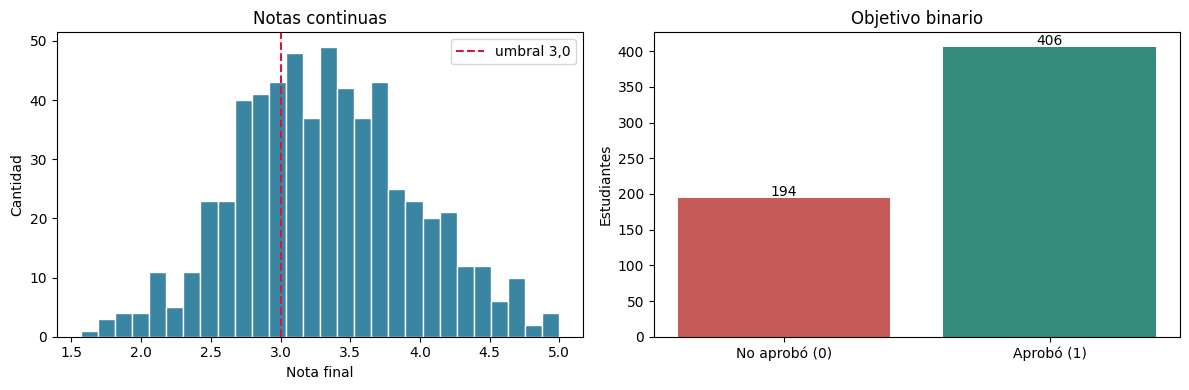

In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(datos['nota_final'],bins=28,color='#3a86a2',edgecolor='white')
ax[0].axvline(3,color='crimson',linestyle='--',label='umbral 3,0')
ax[0].set(xlabel='Nota final',ylabel='Cantidad',title='Notas continuas');ax[0].legend()
conteo=datos['aprobo'].value_counts().sort_index()
ax[1].bar(['No aprobó (0)','Aprobó (1)'],conteo.values,color=['#c55a57','#358b7b'])
for i,v in enumerate(conteo.values):ax[1].text(i,v+3,str(v),ha='center')
ax[1].set(ylabel='Estudiantes',title='Objetivo binario');plt.tight_layout();plt.show()

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> **Panel izquierdo:** cada barra cuenta cuántas notas caen en un intervalo; la línea vertical roja en 3,0 es la regla de aprobación, **no una recta aprendida por el algoritmo**. **Panel derecho:** las alturas son los conteos exactos de clases. Si una clase es más frecuente, un modelo que siempre predice esa clase podría conseguir una exactitud aparentemente aceptable sin aprender mucho; por eso evaluaremos otras métricas.

## 5. Antes de entrenar: separar entrenamiento y prueba y evitar fuga de datos

In [5]:
X=datos[columnas_x].copy()
y=datos['aprobo'].copy()
X_entrena,X_prueba,y_entrena,y_prueba=train_test_split(
    X,y,test_size=0.20,stratify=y,random_state=SEMILLA)
print('X entrenamiento:',X_entrena.shape,'y entrenamiento:',y_entrena.shape)
print('X prueba:',X_prueba.shape,'y prueba:',y_prueba.shape)
print('Proporción de aprobados en entrenamiento:',round(y_entrena.mean(),4))
print('Proporción de aprobados en prueba:',round(y_prueba.mean(),4))

X entrenamiento: (480, 6) y entrenamiento: (480,)
X prueba: (120, 6) y prueba: (120,)
Proporción de aprobados en entrenamiento: 0.6771
Proporción de aprobados en prueba: 0.675


### Interpretación numérica específica de esta ejecución

**Valores de la corrida:** la tabla `X_entrena` tiene forma **(480,6)**: 480 estudiantes y seis predictores; `y_entrena` es `(480,)`, 480 etiquetas. Prueba contiene **120** estudiantes. Las prevalencias **0,6771** y **0,6750** son próximas porque la división fue estratificada. Si una clase escaseara, esta precaución sería especialmente relevante.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> De 600 registros, el 80% (480) se reserva para **entrenar y validar** y el 20% (120) para la **evaluación final**. `stratify=y` intenta preservar la proporción 0/1 en ambas particiones; pequeñas diferencias son normales por redondeos de conteos. **Nunca se deben estandarizar los 600 datos antes de dividirlos**: la media y desviación de prueba no deben influir en el entrenamiento. `random_state=42` permite reproducir la división.

## 6. ¿Por qué no usar regresión lineal para predecir una clase?

In [6]:
recta=LinearRegression().fit(X_entrena[['promedio_anterior']],y_entrena)
valores=np.array([[0.0],[1.0],[2.0],[3.0],[4.0],[5.0],[7.0]])
predicciones=recta.predict(pd.DataFrame(valores,columns=['promedio_anterior']))
display(pd.DataFrame({'promedio_anterior':valores.ravel(),'salida_recta':predicciones}).round(3))
print('Pendiente:',round(recta.coef_[0],4),'intercepto:',round(recta.intercept_,4))

,promedio_anterior,salida_recta
0,0.0,-0.458
1,1.0,-0.118
2,2.0,0.223
3,3.0,0.563
4,4.0,0.904
5,5.0,1.244
6,7.0,1.925


Pendiente: 0.3405 intercepto: -0.458


### Interpretación numérica específica de esta ejecución

**Resultados concretos:** intercepto **−0,4580** y pendiente **0,3405** producen `salida≈−0,4580+0,3405×x`. Por ejemplo, x=5 → **1,244** y x=0 → **−0,458**: ambos fuera del intervalo válido de probabilidades [0,1]. La recta puede acercarse a los valores 0 y 1 dentro de cierto rango, pero no asegura probabilidades válidas fuera de él.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> La regresión lineal minimiza errores cuadrados de un resultado **continuo** y devuelve cualquier número real; sus predicciones para clases binarias no están restringidas a [0,1]. En la tabla, una salida mayor que 1 o menor que 0 **no es una probabilidad válida**. El intercepto es la salida para promedio 0 y la pendiente el cambio por punto adicional de promedio; son parámetros de una recta, no de un clasificador logístico. Las filas 0 y 7 son escenarios matemáticos que pueden quedar fuera del rango de entrenamiento: no deben usarse para decisiones reales.

## 7. De la combinación lineal a la sigmoide

En lugar de interpretar directamente una recta como probabilidad, el modelo calcula un **puntaje** o *logit*:

$$z=\beta_0+\beta_1x_1+\cdots+\beta_px_p$$

Y lo transforma en probabilidad mediante:

$$\sigma(z)=\frac{1}{1+e^{-z}}$$

Si `z=0`, entonces `p=0.5`. Si `z` crece, `p` se acerca a 1; si decrece, se acerca a 0. **El puntaje `z` puede ser cualquier número real, pero la probabilidad siempre está entre 0 y 1**.

,z (logit),exp(-z),p=1/(1+exp(-z)),clase con umbral 0.5
0,-4.0,54.59815,0.01799,0
1,-2.0,7.38906,0.11920,0
2,-1.0,2.71828,0.26894,0
3,0.0,1.00000,0.50000,1
4,1.0,0.36788,0.73106,1
5,2.0,0.13534,0.88080,1
6,4.0,0.01832,0.98201,1


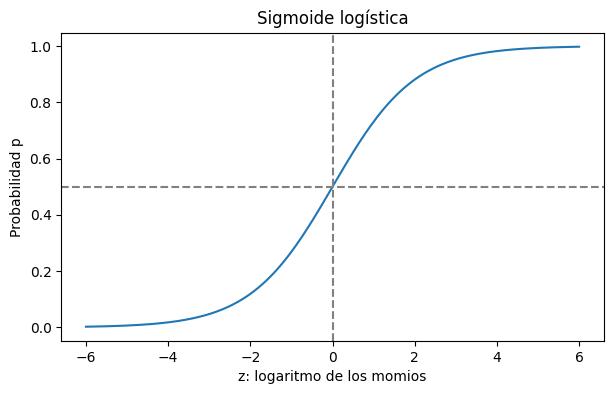

In [7]:
def sigmoide(z):
    z=np.asarray(z,dtype=float)
    return 1/(1+np.exp(-np.clip(z,-500,500)))
z_ejemplo=np.array([-4,-2,-1,0,1,2,4],dtype=float)
probabilidades=sigmoide(z_ejemplo)
display(pd.DataFrame({'z (logit)':z_ejemplo,'exp(-z)':np.exp(-z_ejemplo),
 'p=1/(1+exp(-z))':probabilidades,'clase con umbral 0.5':(probabilidades>=.5).astype(int)}).round(5))
z_malla=np.linspace(-6,6,250)
plt.figure(figsize=(7,4));plt.plot(z_malla,sigmoide(z_malla));plt.axhline(.5,color='gray',ls='--');plt.axvline(0,color='gray',ls='--')
plt.xlabel('z: logaritmo de los momios');plt.ylabel('Probabilidad p');plt.title('Sigmoide logística');plt.show()

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> **Ejemplo de cálculo:** para `z=0`, `exp(0)=1` y `p=1/(1+1)=0,5`. Para `z=2`, `exp(-2)≈0,1353` y `p≈0,8808`; para `z=-2`, `p≈0,1192`. En la columna final, umbral `>=0,5` asigna 1 al caso `z=0` y a todos los positivos. La línea horizontal representa la probabilidad 0,5; la vertical, logit 0. **La sigmoide no convierte automáticamente una probabilidad en un hecho cierto**: un 0,88 sigue implicando incertidumbre.

## 8. Momios (odds), logit y una conversión manual

In [8]:
ps=np.array([0.1,0.2,0.5,0.8,0.9])
odds=ps/(1-ps)
logit=np.log(odds)
display(pd.DataFrame({'p':ps,'1-p':1-ps,'odds=p/(1-p)':odds,'logit=ln(odds)':logit,
 'sigmoide(logit)':sigmoide(logit)}).round(4))

,p,1-p,odds=p/(1-p),logit=ln(odds),sigmoide(logit)
0,0.1,0.9,0.1111,-2.1972,0.1
1,0.2,0.8,0.2500,-1.3863,0.2
2,0.5,0.5,1.0000,0.0000,0.5
3,0.8,0.2,4.0000,1.3863,0.8
4,0.9,0.1,9.0000,2.1972,0.9


> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> Si `p=0,8`, entonces no ocurrir tiene probabilidad 0,2, los **momios** son `0,8/0,2=4`: cuatro a uno a favor del evento, no «400% de probabilidad». El logit es `ln(4)≈1,3863`. Al aplicar la sigmoide a ese logit regresamos exactamente a 0,8. **Probabilidad, momios y logit son escalas diferentes** y no se deben confundir.

## 9. Entropía cruzada: ¿qué está minimizando el entrenamiento?

In [9]:
def perdida_binaria(y_real,p):
    p=np.clip(np.asarray(p),1e-12,1-1e-12)
    y_real=np.asarray(y_real)
    return -(y_real*np.log(p)+(1-y_real)*np.log(1-p))
casos=pd.DataFrame({'y_real':[1,1,0,0,1,0], 'p_estimada':[.90,.20,.10,.80,.50,.50]})
casos['log_loss_individual']=perdida_binaria(casos.y_real,casos.p_estimada)
display(casos.round(4))
print('Log loss medio de los seis ejemplos:',round(casos.log_loss_individual.mean(),4))

,y_real,p_estimada,log_loss_individual
0,1,0.9,0.1054
1,1,0.2,1.6094
2,0,0.1,0.1054
3,0,0.8,1.6094
4,1,0.5,0.6931
5,0,0.5,0.6931


Log loss medio de los seis ejemplos: 0.8026


### Interpretación numérica específica de esta ejecución

**Los seis errores exactos son** 0,1054; 1,6094; 0,1054; 1,6094; 0,6931; 0,6931. Sumarlos da aproximadamente 4,8158 y dividir entre seis produce **0,8026**. Observa que una predicción errónea con confianza 80% cuesta mucho más que una predicción correcta con confianza 90%.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> En la **primera fila** la clase real es 1 y `p=0,90`, por tanto pérdida `-ln(0,90)≈0,1054`, baja porque el modelo dio alta probabilidad al resultado ocurrido. En la **segunda** la clase real es 1 y `p=0,20`: pérdida `-ln(0,20)≈1,6094`, mayor porque el modelo se mostró muy seguro en la dirección equivocada. Para `y=0`, la pérdida es `-ln(1-p)`. Cada fila tiene su costo; el total impreso es el **promedio aritmético de seis pérdidas**, no el porcentaje de errores ni la exactitud. La entropía cruzada castiga mucho las probabilidades confiadas y equivocadas.

## 10. Gradiente y descenso: entrenamiento manual con una sola variable estandarizada

In [10]:
# Demostración matemática con DATOS DE ENTRENAMIENTO, sin usar los de prueba.
col='promedio_anterior'
media_train=X_entrena[col].mean();std_train=X_entrena[col].std(ddof=0)
xz=(X_entrena[col].to_numpy()-media_train)/std_train
Xd=np.c_[np.ones(len(xz)),xz]
yd=y_entrena.to_numpy()
def gradiente(beta,Xmat,yy):
    return Xmat.T@(sigmoide(Xmat@beta)-yy)/len(yy)
def costo(beta,Xmat,yy):
    return perdida_binaria(yy,sigmoide(Xmat@beta)).mean()
beta=np.zeros(2)
log=[]
tasa=.5
for paso in range(1001):
    if paso in (0,1,2,5,10,50,100,500,1000):
        log.append((paso,beta[0],beta[1],costo(beta,Xd,yd),np.linalg.norm(gradiente(beta,Xd,yd))))
    if paso<1000:beta=beta-tasa*gradiente(beta,Xd,yd)
hist=pd.DataFrame(log,columns=['paso','intercepto','pendiente','costo','norma_gradiente'])
display(hist.round(6));print('Media entrenamiento:',round(media_train,4),'desviación:',round(std_train,4))

,paso,intercepto,pendiente,costo,norma_gradiente
0,0,0.000000,0.000000,0.693147,0.269184
1,1,0.088542,0.101367,0.659177,0.235669
2,2,0.166051,0.190121,0.633108,0.206944
3,5,0.347013,0.398182,0.584840,0.144488
4,10,0.538840,0.624123,0.550711,0.087757
5,50,0.897581,1.103401,0.524371,0.007154
6,100,0.933414,1.159161,0.524117,0.000579
7,500,0.936635,1.164249,0.524115,0.000000
8,1000,0.936635,1.164249,0.524115,0.000000


Media entrenamiento: 3.3338 desviación: 0.5954


### Interpretación numérica específica de esta ejecución

**Secuencia observada:** pérdida inicial **0,693147**, después del primer paso **0,659177**, tras diez pasos **0,550711** y al final **0,524115**. Los coeficientes convergen a intercepto **0,936635** y pendiente estandarizada **1,164249**. La norma del gradiente llega a casi cero con el redondeo mostrado. La caída de pérdida demuestra optimización en entrenamiento, **no validación externa**.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> En el **paso 0** ambos coeficientes son 0; entonces `z=0` para todos y la probabilidad inicial es 0,5. Cada iteración actualiza `beta_nuevo = beta_actual − 0,5×gradiente`. `costo` es la pérdida media logística; debe descender si la tasa elegida permite convergencia. `norma_gradiente` mide cuánto empuja todavía el costo a los parámetros: una norma pequeña es señal de proximidad a un punto estacionario, **no prueba de buen rendimiento sobre datos nuevos**. El intercepto y la pendiente corresponden a **promedio estandarizado**, no a una unidad original de nota.

## 11. Comprobar nuestro cálculo contra Scikit-learn

In [11]:
sk_manual=LogisticRegression(penalty=None,max_iter=10000).fit(xz.reshape(-1,1),yd)
beta_sklearn=np.r_[sk_manual.intercept_,sk_manual.coef_.ravel()]
display(pd.DataFrame({'descenso_manual':beta,'scikit_learn':beta_sklearn,
 'diferencia':beta-beta_sklearn},index=['intercepto','promedio_z']).round(6))
print('Máxima diferencia absoluta:',round(np.max(np.abs(beta-beta_sklearn)),6))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,descenso_manual,scikit_learn,diferencia
intercepto,0.936635,0.936618,0.000017
promedio_z,1.164249,1.164463,-0.000215


Máxima diferencia absoluta: 0.000215


### Interpretación numérica específica de esta ejecución

**Comparación numérica:** el intercepto manual **0,936635** frente a **0,936618** difiere solo **0,000017**; la pendiente **1,164249** frente a **1,164463** difiere **−0,000215**. La diferencia máxima absoluta impresa es **0,000215**, confirmación numérica de que el gradiente manual encontró prácticamente el mismo mínimo.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> Las columnas muestran dos métodos de estimación de **la misma función objetivo sin penalización**: descenso del gradiente programado y optimizador de Scikit-learn. La columna `diferencia` es `manual − biblioteca`, y la discrepancia máxima es el valor absoluto más grande entre ambos coeficientes. Pequeñas diferencias numéricas son normales porque un método hizo 1.000 pasos y el otro utiliza otro optimizador/tolerancia. **No debe compararse** con el valor por defecto de `LogisticRegression`, porque este aplica regularización L2.

## 12. Modelo principal: regresión logística múltiple con Pipeline

In [12]:
logistica=Pipeline([('escalador',StandardScaler()),
 ('modelo',LogisticRegression(max_iter=5000,random_state=SEMILLA))])
logistica.fit(X_entrena,y_entrena)
prob_entrena=logistica.predict_proba(X_entrena)[:,1]
prob_prueba=logistica.predict_proba(X_prueba)[:,1]
pred_entrena=logistica.predict(X_entrena)
pred_prueba=logistica.predict(X_prueba)
print('Filas entrenadas:',len(X_entrena),'Filas predichas en prueba:',len(prob_prueba))
print('Primeras cinco probabilidades (clase 1):',np.round(prob_prueba[:5],4))
print('Primeras cinco clases predichas:',pred_prueba[:5])

Filas entrenadas: 480 Filas predichas en prueba: 120
Primeras cinco probabilidades (clase 1): [0.996  0.7608 0.9436 0.971  0.9381]
Primeras cinco clases predichas: [1 1 1 1 1]


### Interpretación numérica específica de esta ejecución

**Salidas concretas:** las cinco probabilidades son **0,9960; 0,7608; 0,9436; 0,9710; 0,9381**: todas exceden el umbral 0,5 y por ello las cinco predicciones son **1**. En particular, 0,7608 no es «76,08% de precisión del modelo»: es la probabilidad asignada a **ese individuo**.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> `fit()` calcula las medias/desviaciones **exclusivamente en entrenamiento** y estima los parámetros del clasificador. `predict_proba()` devuelve una matriz de dos columnas: `P(no aprueba)` y `P(aprueba)`; `[:,1]` selecciona la segunda. Por ejemplo, probabilidad 0,73 significa 73% estimado de pertenecer a clase 1, no 73% de certeza causal. `predict()` usa el umbral convencional de 0,5 para convertir probabilidades en 0/1. **Estas son predicciones sobre 120 observaciones reservadas**, no sus notas reales.

## 13. Interpretación exacta de coeficientes, escalas y odds ratios

In [13]:
est=logistica.named_steps['escalador']
clf=logistica.named_steps['modelo']
coef=clf.coef_[0]
tabla_coef=pd.DataFrame({'variable':columnas_x,
 'media_original':est.mean_, 'desviacion_original':est.scale_,
 'beta_por_1_desviacion':coef,'OR_por_1_desviacion':np.exp(coef),
 'beta_por_1_unidad_original':coef/est.scale_,
 'OR_por_1_unidad_original':np.exp(coef/est.scale_)})
display(tabla_coef.round(4))
print('Intercepto (en predictores estandarizados):',round(clf.intercept_[0],5))

,variable,media_original,desviacion_original,beta_por_1_desviacion,OR_por_1_desviacion,beta_por_1_unidad_original,OR_por_1_unidad_original
0,promedio_anterior,3.3338,0.5954,1.5516,4.7191,2.6058,13.5421
1,horas_estudio_semana,8.8170,4.0517,1.0206,2.7748,0.2519,1.2864
2,asistencia_pct,78.2179,12.1126,0.7181,2.0506,0.0593,1.0611
3,edad,25.1812,5.1759,0.0347,1.0354,0.0067,1.0067
4,estrato,3.4438,1.7299,0.1096,1.1158,0.0633,1.0654
5,trabaja,0.3667,0.4819,-0.3788,0.6847,-0.7861,0.4556


Intercepto (en predictores estandarizados): 1.19734


### Interpretación numérica específica de esta ejecución

**Interpretación de cifras reales:** para `promedio_anterior` beta estandarizado **1,5516** y OR **4,7191**: subir una desviación de promedio, conservando lo demás, multiplica por ~4,72 los **momios** de aprobación. Para `horas_estudio_semana`, la OR por una **hora** es **1,2864**; para `asistencia_pct`, OR por **un punto porcentual** ≈ **1,0611**. Para `trabaja`, OR por el cambio **0→1** ≈ **0,4556**, no 0,6847 (que correspondería a una desviación estándar de la variable binaria). En la simulación, la edad y el estrato no se incorporaron como causas directas al generador; sus coeficientes pueden resultar no nulos por fluctuación y correlación muestral.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> **Cada columna:** `media_original` y `desviacion_original` son las estadísticas de entrenamiento utilizadas por el escalador; `beta_por_1_desviacion` es el cambio en log-momios ante un aumento de **una desviación estándar**, manteniendo las demás variables constantes. `exp(beta)` es la razón de momios: OR>1 implica multiplicación al alza de momios, OR<1 a la baja. `beta_por_1_unidad_original=beta/desviación`; su exponencial corresponde a una unidad original. **Para la variable binaria `trabaja`, el paso 0→1 es UNA unidad original**, por lo que conviene interpretar su OR de la última columna, no el de una desviación estándar. OR=2 no significa que la probabilidad se duplique.

## 14. Construir manualmente una predicción de un estudiante ficticio de la muestra de prueba

In [14]:
fila=X_prueba.iloc[[0]]
x_original=fila.iloc[0].to_numpy()
x_estandarizado=(x_original-est.mean_)/est.scale_
contribuciones=x_estandarizado*coef
z=clf.intercept_[0]+contribuciones.sum()
p_manual=float(sigmoide(z))
p_biblioteca=float(logistica.predict_proba(fila)[0,1])
reporte=pd.DataFrame({'variable':columnas_x,'valor_original':x_original,
 'valor_estandarizado':x_estandarizado,'coeficiente':coef,'contribucion_al_logit':contribuciones})
display(reporte.round(5))
print('Intercepto:',round(clf.intercept_[0],5))
print('Suma de contribuciones:',round(contribuciones.sum(),5))
print('Logit z:',round(z,5))
print('Probabilidad manual:',round(p_manual,6),'probabilidad scikit-learn:',round(p_biblioteca,6))
print('Clase real:',int(y_prueba.iloc[0]),'clase estimada:',int(p_manual>=.5))

,variable,valor_original,valor_estandarizado,coeficiente,contribucion_al_logit
0,promedio_anterior,4.42179,1.82712,1.55162,2.83500
1,horas_estudio_semana,12.81613,0.98703,1.02056,1.00732
2,asistencia_pct,77.73731,-0.03968,0.71813,-0.02849
3,edad,33.00000,1.51060,0.03475,0.05249
4,estrato,6.00000,1.47766,0.10957,0.16190
5,trabaja,0.00000,-0.76089,-0.37883,0.28825


Intercepto: 1.19734
Suma de contribuciones: 4.31647
Logit z: 5.51381
Probabilidad manual: 0.995985 probabilidad scikit-learn: 0.995985
Clase real: 1 clase estimada: 1


### Interpretación numérica específica de esta ejecución

**Cálculo observado paso a paso:** las seis contribuciones son aproximadamente **2,83500 + 1,00732 − 0,02849 + 0,05249 + 0,16190 + 0,28825 = 4,31647**. Añadir intercepto **1,19734** produce `z=5,51381`; la sigmoide da **0,995985**. La clase estimada **1** coincide con la real **1**, pero este acierto individual no justifica por sí solo la calidad global.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> Se resta la **media de entrenamiento** de cada valor y se divide por la desviación de entrenamiento. Después se multiplica por su coeficiente y se suman las seis contribuciones **más el intercepto**. El resultado es `z`, un log-momio; aplicarle `1/(1+exp(-z))` produce `p_manual`. Debe coincidir con `predict_proba`. **Clase real** es la observada en los datos de prueba; **clase estimada** es 1 si p≥0,5, 0 en otro caso. Que un individuo sea predicho incorrectamente no invalida necesariamente el desempeño agregado.

## 15. Matriz de confusión: de 120 casos a cuatro conteos

Matriz (filas: real 0,1; columnas: predicho 0,1):
[[27 12]
 [12 69]]
TN=27; FP=12; FN=12; TP=69; Total=120


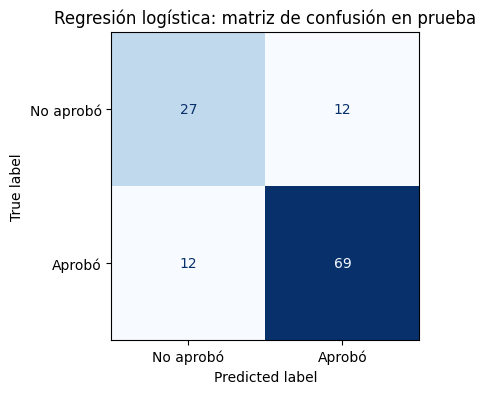

In [15]:
mat=confusion_matrix(y_prueba,pred_prueba,labels=[0,1])
tn,fp,fn,tp=mat.ravel()
print('Matriz (filas: real 0,1; columnas: predicho 0,1):')
print(mat)
print(f'TN={tn}; FP={fp}; FN={fn}; TP={tp}; Total={mat.sum()}')
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(mat,display_labels=['No aprobó','Aprobó']).plot(ax=ax,cmap='Blues',colorbar=False)
plt.title('Regresión logística: matriz de confusión en prueba');plt.show()

### Interpretación numérica específica de esta ejecución

**Casos contabilizados:** **TN=27**, **FP=12**, **FN=12**, **TP=69**. Esto significa 27 no aprobados correctamente identificados y 69 aprobados correctamente identificados: **96 aciertos**. Hubo **24 errores**, repartidos en 12 falsas alarmas positivas y 12 omisiones de aprobados. La suma `27+12+12+69=120` coincide con el tamaño del test.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> La celda superior izquierda es **TN**, estudiantes que no aprobaron y fueron correctamente identificados como 0. Superior derecha **FP**, estudiantes que no aprobaron pero fueron predichos como 1. Inferior izquierda **FN**, aprobados que fueron predichos como 0. Inferior derecha **TP**, aprobados correctamente predichos como 1. La suma de las cuatro celdas debe ser exactamente **120**, el tamaño de prueba. **FP y FN son errores diferentes** y pueden tener consecuencias distintas según el uso del modelo.

## 16. Métricas calculadas a partir de la matriz: ¿qué mide cada una?

- **Exactitud (accuracy)** = `(TP + TN) / (TP + TN + FP + FN)`: proporción de aciertos generales.
- **Precisión positiva (precision)** = `TP / (TP + FP)`: entre quienes el modelo predijo aprobados, proporción que realmente aprobó.
- **Sensibilidad (recall)** = `TP / (TP + FN)`: entre quienes realmente aprobaron, proporción identificada.
- **Especificidad** = `TN / (TN + FP)`: entre los no aprobados reales, proporción correctamente identificada.
- **F1** = `2 × precision × recall / (precision + recall)`: media armónica que combina ambas.

Ninguna de estas fórmulas representa directamente «probabilidad bien calibrada».

In [16]:
exactitud=accuracy_score(y_prueba,pred_prueba)
precision=precision_score(y_prueba,pred_prueba,zero_division=0)
sensibilidad=recall_score(y_prueba,pred_prueba,zero_division=0)
especificidad=tn/(tn+fp)
f1=f1_score(y_prueba,pred_prueba,zero_division=0)
metricas=pd.DataFrame({'metrica':['Accuracy','Precision (clase 1)','Recall/Sensibilidad (clase 1)','Especificidad (clase 0)','F1 (clase 1)'],
 'valor':[exactitud,precision,sensibilidad,especificidad,f1]})
display(metricas.round(4))
print('Cálculos manuales:')
print('Accuracy =',f'({tp}+{tn})/{mat.sum()} = {exactitud:.4f}')
print('Precision =',f'{tp}/({tp}+{fp}) = {precision:.4f}')
print('Recall =',f'{tp}/({tp}+{fn}) = {sensibilidad:.4f}')
print('Especificidad =',f'{tn}/({tn}+{fp}) = {especificidad:.4f}')
print('F1 =',f'2*{precision:.4f}*{sensibilidad:.4f}/({precision:.4f}+{sensibilidad:.4f}) ≈ {f1:.4f}')

,metrica,valor
0,Accuracy,0.8000
1,Precision (clase 1),0.8519
2,Recall/Sensibilidad (clase 1),0.8519
3,Especificidad (clase 0),0.6923
4,F1 (clase 1),0.8519


Cálculos manuales:
Accuracy = (69+27)/120 = 0.8000
Precision = 69/(69+12) = 0.8519
Recall = 69/(69+12) = 0.8519
Especificidad = 27/(27+12) = 0.6923
F1 = 2*0.8519*0.8519/(0.8519+0.8519) ≈ 0.8519


### Interpretación numérica específica de esta ejecución

**Cálculos exactos desde la matriz:** accuracy `96/120=**0,8000**`; precision `69/(69+12)=**0,8519**`; recall `69/(69+12)=**0,8519**`; especificidad `27/(27+12)=**0,6923**`; F1 **0,8519**. **Por qué precision y recall coinciden aquí:** el número de FP y FN es el mismo (12). No es una propiedad universal de la regresión logística.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> La tabla expresa proporciones de 0 a 1. Para convertir a porcentaje, multiplica por 100. **Accuracy** mide aciertos totales, pero puede ser engañosa si la clase 1 es muy frecuente. **Precisión** se centra en las predicciones positivas; **sensibilidad** en los positivos reales; **especificidad** en los negativos reales. F1 no considera TN directamente y por ello no reemplaza a todas las demás métricas. Las operaciones impresas permiten reconstruir cada valor **con las cuatro celdas anteriores**.

## 17. Comparación con una estrategia ingenua: la clase más frecuente

In [17]:
dummy=DummyClassifier(strategy='most_frequent').fit(X_entrena,y_entrena)
pred_dummy=dummy.predict(X_prueba)
comparacion_base=pd.DataFrame([
 {'modelo':'Predice siempre clase más frecuente','accuracy':accuracy_score(y_prueba,pred_dummy),'precision_1':precision_score(y_prueba,pred_dummy,zero_division=0),'recall_1':recall_score(y_prueba,pred_dummy,zero_division=0),'f1_1':f1_score(y_prueba,pred_dummy,zero_division=0)},
 {'modelo':'Regresión logística','accuracy':exactitud,'precision_1':precision,'recall_1':sensibilidad,'f1_1':f1}])
display(comparacion_base.round(4))

,modelo,accuracy,precision_1,recall_1,f1_1
0,Predice siempre clase más frecuente,0.675,0.6750,1.0000,0.8060
1,Regresión logística,0.800,0.8519,0.8519,0.8519


### Interpretación numérica específica de esta ejecución

**Resultado observado:** la regla ingenua obtiene accuracy **0,6750** porque la clase positiva representa 81/120=67,5% de la prueba. Adivina siempre `1`, por lo que recall=**1,0000**, pero esto no significa que distinga bien: ignora completamente a los 39 no aprobados. La regresión logística mejora accuracy a **0,8000**, es decir, **12,5 puntos porcentuales** más.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> El `DummyClassifier` NO aprende relaciones entre las seis características y la aprobación: predice siempre la clase predominante de entrenamiento. Por eso puede tener exactitud alta cuando una clase domina, aunque falle de manera sistemática la clase minoritaria. La diferencia con la logística indica cuánto aporta usar las características. **Un modelo debe compararse con una referencia simple**, no solo celebrar una accuracy aislada.

## 18. Umbral de decisión: ¿por qué 0,50 no es una ley universal?

In [18]:
umbral_resultados=[]
for umbral in [0.20,0.35,0.50,0.65,0.80]:
    p=(prob_prueba>=umbral).astype(int)
    m=confusion_matrix(y_prueba,p,labels=[0,1]); tnn,fpp,fnn,tpp=m.ravel()
    umbral_resultados.append({'umbral':umbral,'TN':tnn,'FP':fpp,'FN':fnn,'TP':tpp,
    'accuracy':accuracy_score(y_prueba,p),'precision':precision_score(y_prueba,p,zero_division=0),
    'recall':recall_score(y_prueba,p,zero_division=0),'F1':f1_score(y_prueba,p,zero_division=0)})
tabla_umbral=pd.DataFrame(umbral_resultados)
display(tabla_umbral.round(4))

,umbral,TN,FP,FN,TP,accuracy,precision,recall,F1
0,0.20,10,29,0,81,0.7583,0.7364,1.0000,0.8482
1,0.35,21,18,7,74,0.7917,0.8043,0.9136,0.8555
2,0.50,27,12,12,69,0.8000,0.8519,0.8519,0.8519
3,0.65,30,9,18,63,0.7750,0.8750,0.7778,0.8235
4,0.80,35,4,28,53,0.7333,0.9298,0.6543,0.7681


### Interpretación numérica específica de esta ejecución

**Resultados concretos del cambio de umbral:** con **0,20** el recall es **1,0000** (ningún FN), pero hay **29 FP**. Con **0,50** hay **12 FP** y **12 FN**, accuracy **0,8000**. Con **0,80** quedan solo **4 FP**, pero aumentan los FN a **28**; precision llega a **0,9298** y recall cae a **0,6543**. **Se intercambian tipos de error**, por eso no debe declararse un mejor umbral sin definir las consecuencias de equivocarse.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> Cada fila cambia **solo el umbral** para decidir 0/1: los coeficientes, el entrenamiento y las probabilidades son idénticos. Al **subir** el umbral, el modelo exige mayor probabilidad para declarar 1; normalmente baja el número de positivos predichos, lo que suele reducir FP, pero puede aumentar FN. Por eso precisión y sensibilidad pueden moverse en sentidos diferentes. Esta tabla es una **demostración didáctica sobre prueba**: en una aplicación real el umbral se decide con validación, no después de explorar repetidamente los 120 casos de prueba.

## 19. Curvas ROC y precisión-recall: desempeño a lo largo de muchos umbrales

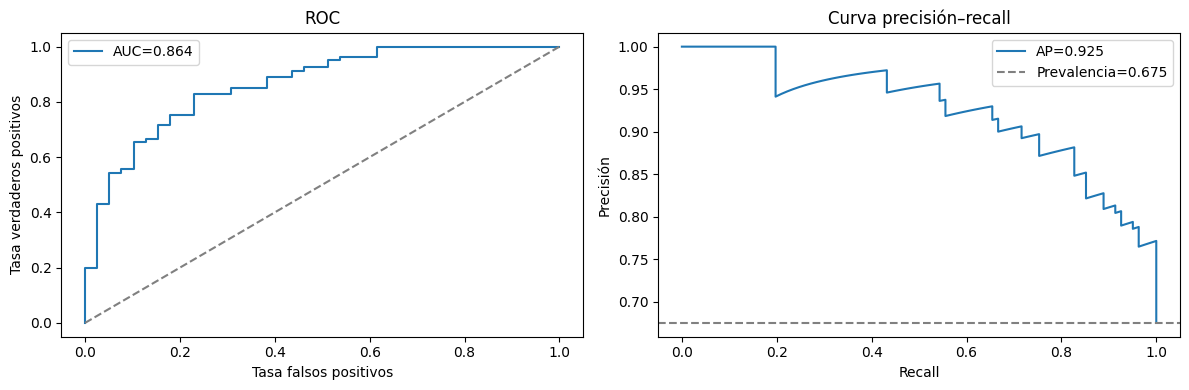

ROC-AUC: 0.8639 Average precision: 0.9253 Prevalencia: 0.675


In [19]:
fpr,tpr,_=roc_curve(y_prueba,prob_prueba)
pr,rec,_=precision_recall_curve(y_prueba,prob_prueba)
auc=roc_auc_score(y_prueba,prob_prueba)
ap=average_precision_score(y_prueba,prob_prueba)
prevalencia=y_prueba.mean()
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(fpr,tpr,label=f'AUC={auc:.3f}');axs[0].plot([0,1],[0,1],'--',color='gray');axs[0].set(xlabel='Tasa falsos positivos',ylabel='Tasa verdaderos positivos',title='ROC');axs[0].legend()
axs[1].plot(rec,pr,label=f'AP={ap:.3f}');axs[1].axhline(prevalencia,color='gray',ls='--',label=f'Prevalencia={prevalencia:.3f}');axs[1].set(xlabel='Recall',ylabel='Precisión',title='Curva precisión–recall');axs[1].legend()
plt.tight_layout();plt.show()
print('ROC-AUC:',round(auc,4),'Average precision:',round(ap,4),'Prevalencia:',round(prevalencia,4))

### Interpretación numérica específica de esta ejecución

**Resultados observados:** ROC-AUC **0,8639**, AP **0,9253** y prevalencia positiva **0,6750**. AUC indica una discriminación mejor que la referencia aleatoria ≈0,5; AP supera la prevalencia como referencia básica del ranking PR. No corresponde decir «el modelo tiene 92,53% de accuracy» cuando AP=0,9253.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> **ROC:** eje X es `FP/(FP+TN)` y eje Y es `TP/(TP+FN)` para diferentes umbrales. AUC resume la capacidad del modelo de ordenar positivos por encima de negativos; 0,5 ≈ azar en condiciones habituales, 1 = separación perfecta. **PR:** eje X es recall y Y es precision; la línea horizontal corresponde a la prevalencia positiva de **este conjunto de prueba** como referencia. `Average precision` integra un resumen escalonado de la curva PR; **no es la misma operación** que el área trapezoidal ni una accuracy. Estas métricas evalúan discriminación, no necesariamente calibración.

## 20. ¿Una probabilidad de 0,8 equivale realmente a 80% de frecuencia? Calibración

In [20]:
print('Log loss de prueba:',round(log_loss(y_prueba,prob_prueba),4))
print('Brier score de prueba:',round(brier_score_loss(y_prueba,prob_prueba),4))
calib=pd.DataFrame({'p':prob_prueba,'y':y_prueba.to_numpy()})
calib['banda']=pd.cut(calib.p,bins=np.linspace(0,1,6),include_lowest=True)
resumen_calib=calib.groupby('banda',observed=False).agg(n=('y','size'),p_media=('p','mean'),tasa_real=('y','mean'))
display(resumen_calib.round(4))

Log loss de prueba: 0.4221
Brier score de prueba: 0.138


,n,p_media,tasa_real
banda,,,
"(-0.001, 0.2]",10,0.0764,0.0000
"(0.2, 0.4]",21,0.2831,0.4286
"(0.4, 0.6]",11,0.4795,0.4545
"(0.6, 0.8]",21,0.7193,0.6667
"(0.8, 1.0]",57,0.9305,0.9298


### Interpretación numérica específica de esta ejecución

**Resultados observados:** log loss **0,4221** y Brier **0,1380**. En la banda 0,8–1,0 hay **57** estudiantes, con probabilidad media **0,9305** y aprobación observada **0,9298**: cercanía entre ambas. En 0,2–0,4 hay **21** casos: probabilidad media **0,2831** frente a tasa observada **0,4286**, diferencia marcada. Estas diferencias no prueban mala calibración global: los grupos son pequeños.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> `Log loss` promedia la pérdida logarítmica de **cada probabilidad**; valores más pequeños indican mejores probabilidades en esa muestra. `Brier` promedia `(p−y)^2`, también menor es mejor. En la tabla de bandas, `n` es el número de estudiantes cuyas predicciones caen en ese rango, `p_media` es la probabilidad promedio del grupo y `tasa_real` la fracción que efectivamente aprobó. Si `p_media≈tasa_real`, hay indicio de calibración en esa banda, **pero bandas con pocos casos tienen alta incertidumbre**.

## 21. Validación cruzada estratificada: evaluar estabilidad sin tocar la prueba

In [21]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEMILLA)
puntuaciones=cross_validate(logistica,X_entrena,y_entrena,cv=cv,
 scoring={'accuracy':'accuracy','f1':'f1','roc_auc':'roc_auc','logloss':'neg_log_loss'},
 return_train_score=True,n_jobs=None)
tabla_cv=pd.DataFrame({'pliegue':np.arange(1,6),
 'accuracy_validacion':puntuaciones['test_accuracy'],
 'f1_validacion':puntuaciones['test_f1'],
 'auc_validacion':puntuaciones['test_roc_auc'],
 'logloss_validacion':-puntuaciones['test_logloss'],
 'accuracy_entrenamiento':puntuaciones['train_accuracy']})
display(tabla_cv.round(4))
print('Media accuracy validación:',round(tabla_cv.accuracy_validacion.mean(),4))
print('Desv. std accuracy validación:',round(tabla_cv.accuracy_validacion.std(ddof=0),4))

,pliegue,accuracy_validacion,f1_validacion,auc_validacion,logloss_validacion,accuracy_entrenamiento
0,1,0.7500,0.8261,0.8372,0.4810,0.8099
1,2,0.7604,0.8345,0.8179,0.4753,0.7891
2,3,0.7812,0.8421,0.8769,0.4138,0.7891
3,4,0.8333,0.8769,0.9072,0.3607,0.7839
4,5,0.8021,0.8571,0.8680,0.4142,0.7812


Media accuracy validación: 0.7854
Desv. std accuracy validación: 0.0299


### Interpretación numérica específica de esta ejecución

**Cinco corridas observadas:** accuracy **0,7500; 0,7604; 0,7812; 0,8333; 0,8021**. Su promedio es **0,7854** y desviación estándar poblacional entre pliegues **0,0299**. La diferencia entre el máximo y el mínimo es **0,0833** (8,33 puntos porcentuales). El pliegue 4 dio el mejor accuracy, pero no se elige como «el único modelo bueno»; su resultado depende de qué registros quedaron en validación.

> **LECTURA DOCENTE DE LA SALIDA ANTERIOR**
>
> Los 480 registros de entrenamiento se dividen en **cinco pliegues estratificados**. En cada corrida, el modelo se ajusta sobre aproximadamente 384 y valida sobre aproximadamente 96. `accuracy_validacion` cambia porque cada pliegue tiene observaciones distintas; **no** son cinco modelos que deban promediar sus coeficientes para predecir. `logloss_validacion` se multiplicó por −1 porque Scikit-learn reporta `neg_log_loss` para mantener la convención «mayor es mejor» de sus puntuadores; la pérdida real sigue siendo positiva. La media resume desempeño, la desviación entre pliegues refleja variabilidad observada (no incertidumbre completa). **Los 120 ejemplos de prueba no participan en esta validación.**

## 22. Precauciones metodológicas: qué resultados NO significan

1. **Predicción no es causalidad.** Un coeficiente positivo en datos sintéticos no prueba que aumentar una variable provoque aprobar.
2. **Un odds ratio no es riesgo relativo.** OR=2 significa duplicar momios, no necesariamente la probabilidad.
3. **Accuracy no es probabilidad calibrada.** Un modelo puede acertar etiquetas y estimar probabilidades deficientes.
4. **No hay un umbral óptimo universal.** Depende del costo de FP/FN y del contexto.
5. **La validación cruzada no usa el test final.** Las decisiones de selección deben tomarse antes de evaluarlo.
6. **Los datos repetidos por estudiante requieren agrupación.** Si hay varios registros del mismo estudiante, conviene dividir por estudiante (`GroupKFold` o separación agrupada), no al azar por fila.
7. **Los datos temporales necesitan validación temporal.** Para predicción futura, no entrenar con observaciones posteriores a la fecha de pronóstico.
8. **No usar datos ficticios para decisiones sobre personas.** Esta base solo demuestra procedimientos matemáticos y computacionales.

## 23. Preguntas para discutir al final de la clase

1. ¿Por qué el objetivo `aprobo` obliga a pasar de regresión numérica a clasificación?
2. ¿Qué diferencia existe entre logit, probabilidad y clase pronosticada?
3. Calcule manualmente la probabilidad cuando z=−1,5 y verifique con Python.
4. ¿Por qué un clasificador siempre-positivo puede exhibir accuracy relativamente alta?
5. Elija un FP y un FN de la matriz de confusión: ¿en qué se diferencian?
6. Compare precision y recall cuando el umbral pasa de 0,35 a 0,65. ¿Qué cambia y por qué?
7. ¿Qué significa el OR de la variable `trabaja` por unidad original?
8. ¿Por qué el escalado debe aprenderse solamente del entrenamiento?
9. ¿Qué indica un `log_loss` elevado si el accuracy es aceptable?
10. ¿Cómo evitarías ajustar un umbral usando repetidamente la prueba final?
11. ¿Cuándo utilizarías regresión logística multinomial en lugar de binaria?
12. ¿Qué método usarías si cada estudiante aparece en varias filas y por qué?

## 24. Síntesis docente: ¿cuándo usar regresión logística y cómo interpretar un modelo completo?

**Cuándo usarla.** El objetivo debe ser categórico: por ejemplo, `aprobo` = 0 o 1. La regresión logística estima la probabilidad condicionada a las características observadas. Una variable cuantitativa como nota final no se predice directamente con este clasificador; si interesa estimar la nota numérica, se usa un modelo de regresión.

**En qué orden trabajar.** (1) Definir la clase positiva y las variables disponibles antes de tomar una decisión; (2) explorar datos y su calidad; (3) separar prueba sin contaminarla; (4) aprender transformaciones sobre entrenamiento mediante `Pipeline`; (5) ajustar coeficientes con `fit()` minimizando pérdida logarítmica con regularización por defecto; (6) interpretar probabilidades y coeficientes; (7) establecer umbral según el costo de errores; (8) validar en el entrenamiento, y finalmente (9) evaluar una sola vez sobre prueba reservada.

**Cómo leer una predicción.** Un coeficiente cambia el *logaritmo de los momios* por unidad de predictor estandarizado, manteniendo los otros predictores constantes. La sigmoide transforma el puntaje lineal a un número entre 0 y 1. Ese número no es una calificación ni equivale a certeza individual.

**Cómo decidir si el modelo es bueno.** Es necesario evaluar desempeño fuera de entrenamiento, compararlo contra un referente ingenuo, revisar el número absoluto de falsos positivos y negativos, la precisión y sensibilidad por clase, la discriminación entre clases y la calibración de probabilidades. Una sola métrica nunca determina por sí sola la utilidad de un clasificador.

**Limitaciones:** la base es sintética; no hay inferencia causal, validación externa ni fundamento para aplicar estas predicciones en decisiones académicas reales.

## Apéndice A. Extensión multinomial: softmax, tres clases

El notebook de referencia también presenta **softmax**. Cuando la etiqueta tiene tres clases mutuamente excluyentes, se utilizan tres puntajes y la probabilidad de cada clase es su exponencial dividida entre la suma de las tres exponenciales. Las probabilidades deben sumar 1 por fila.

**Ejemplo:** modelaremos tres perfiles sintéticos de demanda de servicios (baja, media, alta) a partir de dos características ficticias; aquí no utilizamos el objetivo de aprobación binaria.

In [22]:
from sklearn.datasets import make_blobs
Xm,ym=make_blobs(n_samples=360,centers=[[-2,-1],[2,0],[0,3]],cluster_std=1.15,random_state=SEMILLA)
multiclase=Pipeline([('escalador',StandardScaler()),('modelo',LogisticRegression(max_iter=5000))])
Xm_tr,Xm_te,ym_tr,ym_te=train_test_split(Xm,ym,test_size=.20,stratify=ym,random_state=SEMILLA)
multiclase.fit(Xm_tr,ym_tr)
p_multi=multiclase.predict_proba(Xm_te)
print('Tamaño de matriz de probabilidades:',p_multi.shape)
print('Primeras cinco filas de probabilidades:')
display(pd.DataFrame(p_multi[:5],columns=['P(clase 0)','P(clase 1)','P(clase 2)']).round(4))
print('Suma de cada una de las primeras cinco filas:',np.round(p_multi[:5].sum(axis=1),6))
print('Exactitud de prueba:',round(multiclase.score(Xm_te,ym_te),4))

Tamaño de matriz de probabilidades: (72, 3)
Primeras cinco filas de probabilidades:


,P(clase 0),P(clase 1),P(clase 2)
0,0.0111,0.0079,0.9810
1,0.0111,0.0001,0.9889
2,0.0059,0.0360,0.9581
3,0.0145,0.9827,0.0028
4,0.0090,0.0008,0.9902


Suma de cada una de las primeras cinco filas: [1. 1. 1. 1. 1.]
Exactitud de prueba: 0.9444


**Interpretación:** `(72, 3)` significa 72 registros de prueba, cada uno con tres probabilidades. En una fila, por ejemplo, P0+P1+P2=1, aunque los sumandos individuales cambian. `argmax` determina la clase más probable. La exactitud final es la fracción de esas 72 clases acertadas; **no** significa que todas las probabilidades estén calibradas. La extensión `softmax` es un caso de regresión logística multinomial y **no** un árbol de decisión.

## Apéndice B. Separación perfecta y por qué la regularización importa

Si una combinación de predictores separa sin errores las dos clases de entrenamiento, la regresión logística sin regularización puede empujar sus coeficientes a valores cada vez mayores para acercar las probabilidades a 0 o 1. La función de costo puede acercarse a cero sin alcanzar un óptimo finito. La penalización L2 desalienta coeficientes extremos.

In [23]:
Xs,ys=make_blobs(n_samples=120,centers=[[-3,0],[3,0]],cluster_std=.5,random_state=SEMILLA)
Xs_d=np.c_[np.ones(len(Xs)),Xs]
b_sep=np.array([0.,1.,0.])
filas=[]
for escala in [1,2,4,8,16,32]:
   p_sep=sigmoide(Xs_d@(escala*b_sep))
   filas.append({'multiplicador_coeficiente':escala,'log_loss':perdida_binaria(ys,p_sep).mean()})
display(pd.DataFrame(filas).round(8))
con_l2=LogisticRegression(C=1.0,max_iter=5000).fit(Xs,ys)
print('Norma de parámetros regularizados:',round(np.linalg.norm(np.r_[con_l2.intercept_,con_l2.coef_.ravel()]),4))
print('Exactitud de entrenamiento:',round(con_l2.score(Xs,ys),4))

,multiplicador_coeficiente,log_loss
0,1,0.052035
1,2,0.003442
2,4,0.000022
3,8,0.000000
4,16,0.000000
5,32,0.000000


Norma de parámetros regularizados: 1.816
Exactitud de entrenamiento: 1.0


**Lectura numérica:** `multiplicador_coeficiente` aumenta sin cambiar la dirección del hiperplano separador. El costo disminuye porque la sigmoide entrega probabilidades cada vez más extremas y correctas en esta muestra. Eso no significa que tenga sentido elegir coeficientes infinitos: se vuelven inestables y las probabilidades extremas pueden generalizar mal. `C=1` impone regularización L2 finita (en Scikit-learn, **menor C implica mayor regularización**). La norma final indica magnitud del vector de coeficientes; no debe interpretarse como accuracy.

## Bibliografía y lecturas de referencia (APA 7)

Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer. https://link.springer.com/book/9780387310732

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

Scikit-learn developers. (s. f.). *Logistic regression*. https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

Scikit-learn developers. (s. f.). *Cross-validation: Evaluating estimator performance*. https://scikit-learn.org/stable/modules/cross_validation.html